# 深度 Q 学习 - 月球登陆器

在本次作业中，你将训练一个智能体，让月球登陆器安全地降落在月球表面的着陆坪上。


# 大纲
- [ 1 - 导入软件包 <img align="Right" src="./images/lunar_lander.gif" width = 60% >](#1)
- [ 2 - 超参数](#2)
- [ 3 - 月球登陆器环境](#3)
  - [ 3.1 动作空间](#3.1)
  - [ 3.2 观测空间](#3.2)
  - [ 3.3 奖励](#3.3)
  - [ 3.4 回合终止](#3.4)
- [ 4 - 加载环境](#4)
- [ 5 - 与 Gym 环境交互](#5)
    - [ 5.1 探索环境的动力学](#5.1)
- [ 6 - 深度 Q 学习](#6)
  - [ 6.1 目标网络](#6.1)
    - [ 练习 1](#ex01)
  - [ 6.2 经验回放](#6.2)
- [ 7 - 带经验回放的深度 Q 学习算法](#7)
  - [ 练习 2](#ex02)
- [ 8 - 更新网络权重](#8)
- [ 9 - 训练智能体](#9)
- [ 10 - 观看训练好的智能体实战](#10)
- [ 11 - 恭喜完成！](#11)
- [ 12 - 参考文献](#12)


_**注意：** 为防止自动评分器报错，你不得编辑或删除本实验中不参与评分的单元格。也请不要添加任何新单元格。
**一旦你通过了本次作业** 并想试验任何不参与评分的代码，你可以按照本笔记本底部的说明操作。_

<a name="1"></a>
## 1 - 导入软件包

我们将使用以下软件包：
- `numpy` 是 python 中用于科学计算的软件包。
- `deque` 将是我们内存缓冲区的数据结构。
- `namedtuple` 将用于存储经验元组。
- `gym` 工具包是一个环境的集合，可用于测试强化学习算法。我们应注意，在本笔记本中我们使用的是 `gym` 的 `0.24.0` 版本。
- 渲染月球登陆器环境需要 `PIL.Image` 和 `pyvirtualdisplay`。
- 我们将使用来自 `tensorflow.keras` 框架的若干模块来构建深度学习模型。
- `utils` 是一个包含本次作业辅助函数的模块。你不需要修改这个文件中的代码。

运行下面的单元格来导入所有必要的软件包。

In [1]:
import time
from collections import deque, namedtuple

import gym
import numpy as np
import PIL.Image
import tensorflow as tf
import utils

from pyvirtualdisplay import Display
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.losses import MSE
from tensorflow.keras.optimizers import Adam

Additionally, Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
# Set up a virtual display to render the Lunar Lander environment.
# Display(visible=0, size=(840, 480)).start(); # Only for Linux

# Set the random seed for TensorFlow
tf.random.set_seed(utils.SEED)

<a name="2"></a>
## 2 - 超参数

运行下面的单元格来设置超参数。

In [3]:
MEMORY_SIZE = 100_000     # size of memory buffer
GAMMA = 0.995             # discount factor
ALPHA = 1e-3              # learning rate  
NUM_STEPS_FOR_UPDATE = 4  # perform a learning update every C time steps

<a name="3"></a>
## 3 - 月球登陆器环境

在本笔记本中，我们将使用 [OpenAI 的 Gym 库](https://www.gymlibrary.dev/)。Gym 库提供了各种各样的强化学习环境。简单来说，一个环境代表一个待解决的问题或任务。在本笔记本中，我们将尝试用强化学习来解决月球登陆器环境。

月球登陆器环境的目标是让月球登陆器安全地降落在月球表面的着陆坪上。着陆坪由两根旗杆标示，其中心位于坐标 `(0,0)`，但登陆器也允许降落在着陆坪之外。登陆器从环境的顶部中央开始，其质心上施加了一个随机的初始力，并且拥有无限的燃料。如果你得到 `200` 分，该环境即被视为已解决。

<br>
<br>
<figure>
  <img src = "images/lunar_lander.gif" width = 40%>
      <figcaption style = "text-align: center; font-style: italic">图 1. 月球登陆器环境。</figcaption>
</figure>



<a name="3.1"></a>
### 3.1 动作空间

智能体有四个可用的离散动作：

* 什么都不做。
* 点燃右侧引擎。
* 点燃主引擎。
* 点燃左侧引擎。

每个动作都有一个对应的数值：

```python
Do nothing = 0
Fire right engine = 1
Fire main engine = 2
Fire left engine = 3
```

<a name="3.2"></a>
### 3.2 观测空间

智能体的观测空间由一个含 8 个变量的状态向量构成：

* 它的 $(x,y)$ 坐标。着陆坪始终位于坐标 $(0,0)$。
* 它的线速度 $(\dot x,\dot y)$。
* 它的角度 $\theta$。
* 它的角速度 $\dot \theta$。
* 两个布尔值 $l$ 和 $r$，表示每条腿是否与地面接触。

<a name="3.3"></a>
### 3.3 奖励

每一步之后都会授予一个奖励。一个回合的总奖励是该回合内所有步骤奖励之和。

对每一步，奖励：
- 随登陆器越接近/远离着陆坪而增加/减少。
- 随登陆器移动越慢/越快而增加/减少。
- 随登陆器倾斜越多（角度不水平）而减少。
- 每条与地面接触的腿增加 10 分。
- 侧引擎每点燃一帧减少 0.03 分。
- 主引擎每点燃一帧减少 0.3 分。

对于坠毁或安全着陆，该回合分别会额外收到 -100 或 +100 分的奖励。

<a name="3.4"></a>
### 3.4 回合终止

在下列情况下，一个回合结束（即环境进入终止状态）：

* 月球登陆器坠毁（即月球登陆器的机体与月球表面接触）。

* 登陆器 $x$ 坐标的绝对值大于 1（即它超出了左边界或右边界）

你可以查看 [Open AI Gym 文档](https://www.gymlibrary.dev/environments/box2d/lunar_lander/)，以获取关于该环境的完整描述。

<a name="4"></a>
## 4 - 加载环境

我们首先使用 `.make()` 方法从 `gym` 库加载 `LunarLander-v2` 环境。`LunarLander-v2` 是月球登陆器环境的最新版本，你可以在 [Open AI Gym 文档](https://www.gymlibrary.dev/environments/box2d/lunar_lander/#version-history) 中阅读它的版本历史。

In [4]:
env = gym.make('LunarLander-v2')

<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type swigvarlink has no __module__ attribute


一旦我们加载了环境，就使用 `.reset()` 方法把环境重置为初始状态。登陆器从环境的顶部中央开始，我们可以使用 `.render()` 方法渲染环境的第一帧。

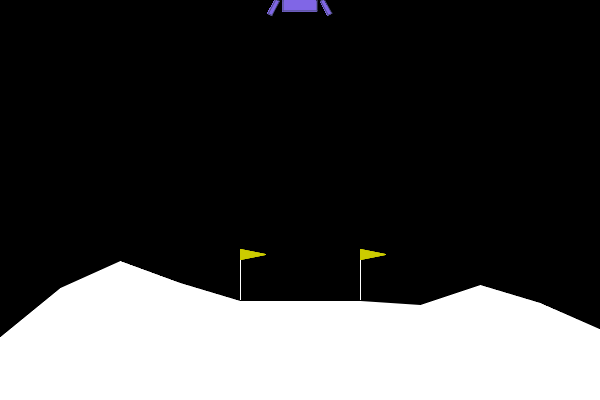

: 

In [ ]:
env.reset()
PIL.Image.fromarray(env.render(mode='rgb_array'))

为了稍后构建我们的神经网络，我们需要知道状态向量的大小和有效动作的数量。我们可以分别从环境中的 `.observation_space.shape` 和 `action_space.n` 方法获取这些信息。

In [6]:
state_size = env.observation_space.shape
num_actions = env.action_space.n

print('State Shape:', state_size)
print('Number of actions:', num_actions)

State Shape: (8,)
Number of actions: 4


<a name="5"></a>
## 5 - 与 Gym 环境交互

Gym 库实现了标准的"智能体-环境循环"（agent-environment loop）形式化：

<br>
<center>
<video src = "./videos/rl_formalism.m4v" width="840" height="480" controls autoplay loop poster="./images/rl_formalism.png"> </video>
<figcaption style = "text-align:center; font-style:italic">图 2. 智能体-环境循环形式化。</figcaption>
</center>
<br>

在标准的"智能体-环境循环"形式化中，智能体在离散时间步 $t=0,1,2,...$ 与环境交互。在每个时间步 $t$，智能体使用一个策略 $\pi$，基于它对环境状态 $S_t$ 的观测来选择一个动作 $A_t$。智能体收到一个数值奖励 $R_t$，并在下一个时间步移动到一个新状态 $S_{t+1}$。

<a name="5.1"></a>
### 5.1 探索环境的动力学

在 Open AI 的 Gym 环境中，我们使用 `.step()` 方法来运行环境动力学的单个时间步。在我们所用的 `gym` 版本中，`.step()` 方法接收一个动作并返回四个值：

* `observation`（**object**）：一个环境特有的对象，表示你对环境的观测。在月球登陆器环境中，这对应于一个 numpy 数组，包含登陆器的位置和速度，如第 [3.2 观测空间](#3.2) 节所述。


* `reward`（**float**）：作为采取给定动作的结果而返回的奖励量。在月球登陆器环境中，这对应于一个 `numpy.float64` 类型的浮点数，如第 [3.3 奖励](#3.3) 节所述。


* `done`（**boolean**）：当 done 为 `True` 时，它表示回合已经终止，是时候重置环境了。


* `info`（**dictionary**）：用于调试的诊断信息。我们在本笔记本中不会使用这个变量，但为了完整性在这里展示它。

要开始一个回合，我们需要把环境重置为初始状态。我们通过使用 `.reset()` 方法来做到这一点。

In [7]:
# Reset the environment and get the initial state.
current_state = env.reset()

一旦环境被重置，智能体就可以通过使用 `.step()` 方法在环境中开始采取动作。请注意，智能体每个时间步只能采取一个动作。

在下面的单元格中，你可以选择不同的动作，看看返回的值如何随所采取的动作而变化。记住，在这个环境中智能体有四个可用的离散动作，我们在代码中通过使用它们对应的数值来指定它们：

```python
Do nothing = 0
Fire right engine = 1
Fire main engine = 2
Fire left engine = 3
```

In [8]:
# Select an action
action = 0

# Run a single time step of the environment's dynamics with the given action.
next_state, reward, done, _ = env.step(action)

# Display table with values.
utils.display_table(current_state, action, next_state, reward, done)

# Replace the `current_state` with the state after the action is taken
current_state = next_state

在实践中，当我们训练智能体时，我们使用一个循环来让智能体在一个回合中采取许多连续的动作。

<a name="6"></a>
## 6 - 深度 Q 学习

在状态空间和动作空间都是离散的情况下，我们可以使用贝尔曼方程迭代地估计动作值函数：

$$
Q_{i+1}(s,a) = R + \gamma \max_{a'}Q_i(s',a')
$$

当 $i\to\infty$ 时，这个迭代方法收敛到最优动作值函数 $Q^*(s,a)$。这意味着智能体只需要逐渐探索状态-动作空间，并不断更新 $Q(s,a)$ 的估计，直到它收敛到最优动作值函数 $Q^*(s,a)$。然而，在状态空间连续的情况下，探索整个状态-动作空间在实践中变得几乎不可能。因此，这也使得逐渐估计 $Q(s,a)$ 直到它收敛到 $Q^*(s,a)$ 在实践中几乎不可能。

在深度 $Q$ 学习中，我们通过使用一个神经网络来估计动作值函数 $Q(s,a)\approx Q^*(s,a)$ 来解决这个问题。我们把这个神经网络称为 $Q$ 网络，它可以通过在每次迭代时调整其权重来训练，以最小化贝尔曼方程中的均方误差。

不幸的是，在强化学习中使用神经网络来估计动作值函数已被证明是高度不稳定的。幸运的是，有几种技术可以被采用来避免不稳定。这些技术包括使用一个***目标网络（Target Network）***和***经验回放（Experience Replay）***。我们将在接下来的小节中探索这两种技术。

<a name="6.1"></a>
### 6.1 目标网络

我们可以通过在每次迭代时调整 $Q$ 网络的权重来训练它，以最小化贝尔曼方程中的均方误差，其中目标值由下式给出：

$$
y = R + \gamma \max_{a'}Q(s',a';w)
$$

其中 $w$ 是 $Q$ 网络的权重。这意味着我们在每次迭代时调整权重 $w$，以最小化下面的误差：

$$
\overbrace{\underbrace{R + \gamma \max_{a'}Q(s',a'; w)}_{\rm {y~target}} - Q(s,a;w)}^{\rm {Error}}
$$

请注意，这构成了一个问题，因为 $y$ 目标在每次迭代时都在变化。拥有一个不断移动的目标会导致振荡和不稳定。为避免这一点，我们可以创建
一个单独的神经网络来生成 $y$ 目标。我们把这个单独的神经网络称为**目标 $\hat Q$ 网络**，它将与原始 $Q$ 网络具有相同的架构。通过使用目标 $\hat Q$ 网络，上面的误差变成：

$$
\overbrace{\underbrace{R + \gamma \max_{a'}\hat{Q}(s',a'; w^-)}_{\rm {y~target}} - Q(s,a;w)}^{\rm {Error}}
$$

其中 $w^-$ 和 $w$ 分别是目标 $\hat Q$ 网络和 $Q$ 网络的权重。

在实践中，我们将使用以下算法：每 $C$ 个时间步，我们将使用 $\hat Q$ 网络来生成 $y$ 目标，并使用 $Q$ 网络的权重来更新目标 $\hat Q$ 网络的权重。我们将使用一次**软更新（soft update）**来更新目标 $\hat Q$ 网络的权重 $w^-$。这意味着我们将使用下面的规则来更新权重 $w^-$：

$$
w^-\leftarrow \tau w + (1 - \tau) w^-
$$

其中 $\tau\ll 1$。通过使用软更新，我们确保目标值 $y$ 缓慢变化，这极大地改进我们学习算法的稳定性。

<a name="ex01"></a>
### 练习 1

在本练习中，你将创建 $Q$ 网络和目标 $\hat Q$ 网络并设置优化器。记住，深度 $Q$ 网络（DQN）是一个近似动作值函数 $Q(s,a)\approx Q^*(s,a)$ 的神经网络。它通过学习如何把状态映射到 $Q$ 值来做到这一点。

为了解决月球登陆器环境，我们将采用一个具有以下架构的 DQN：

* 一个以 `state_size` 为输入的 `Input` 层。

* 一个带 `64` 个单元和 `relu` 激活函数的 `Dense` 层。

* 一个带 `64` 个单元和 `relu` 激活函数的 `Dense` 层。

* 一个带 `num_actions` 个单元和 `linear` 激活函数的 `Dense` 层。这将是我们网络的输出层。


在下面的单元格中，你应使用上面描述的模型架构创建 $Q$ 网络和目标 $\hat Q$ 网络。记住，$Q$ 网络和目标 $\hat Q$ 网络具有相同的架构。

最后，你应把 `Adam` 设为优化器，学习率等于 `ALPHA`。回顾 `ALPHA` 在[超参数](#2)一节中被定义。我们应注意，对于本练习你应使用已经导入的软件包：
```python
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
```

In [9]:
# UNQ_C1
# GRADED CELL

# Create the Q-Network
q_network = Sequential([
    ### START CODE HERE ### 
    Input(state_size),
    Dense(64,activation='relu'),
    Dense(64,activation='relu'),
    Dense(num_actions,activation='linear')
    
    ### END CODE HERE ### 
    ])

# Create the target Q^-Network
target_q_network = Sequential([
    ### START CODE HERE ### 
    Input(state_size),
    Dense(64,activation='relu'),
    Dense(64,activation='relu'),
    Dense(num_actions,activation='linear')   
    
    ### END CODE HERE ###
    ])

### START CODE HERE ### 
optimizer = Adam(ALPHA)
### END CODE HERE ###

In [10]:
# UNIT TEST
from public_tests import *

test_network(q_network)
test_network(target_q_network)
test_optimizer(optimizer, ALPHA) 

All tests passed!
All tests passed!
All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
```python
# Create the Q-Network
q_network = Sequential([
    Input(shape=state_size),                      
    Dense(units=64, activation='relu'),            
    Dense(units=64, activation='relu'),            
    Dense(units=num_actions, activation='linear'),
    ])

# Create the target Q^-Network
target_q_network = Sequential([
    Input(shape=state_size),                       
    Dense(units=64, activation='relu'),            
    Dense(units=64, activation='relu'),            
    Dense(units=num_actions, activation='linear'), 
    ])

optimizer = Adam(learning_rate=ALPHA)                                  
``` 

<a name="6.2"></a>
### 6.2 经验回放

当智能体与环境交互时，智能体所经历的状态、动作和奖励本质上是顺序的。如果智能体试图从这些连续的经验中学习，它可能会遇到问题，因为它们之间存在很强的相关性。为避免这一点，我们采用一种称为**经验回放（Experience Replay）**的技术，来为训练我们的智能体生成不相关的经验。经验回放包括把智能体的经验（即智能体收到的状态、动作和奖励）存储在一个内存缓冲区中，然后从缓冲区中抽取一个随机的小批量经验来进行学习。经验元组 $(S_t, A_t, R_t, S_{t+1})$ 会在智能体与环境交互时的每个时间步被添加到内存缓冲区中。

为了方便起见，我们将把经验存储为具名元组（named tuples）。

In [11]:
# Store experiences as named tuples
experience = namedtuple("Experience", field_names=["state", "action", "reward", "next_state", "done"])

通过使用经验回放，我们避免了有问题的相关性、振荡和不稳定。此外，经验回放还允许智能体可能在多次权重更新中使用同一次经验，这提高了数据效率。

<a name="7"></a>
## 7 - 带经验回放的深度 Q 学习算法

既然我们知道了将要使用的所有技术，我们就可以把它们组合起来，得到带经验回放的深度 Q 学习算法。
<br>
<br>
<figure>
  <img src = "images/deep_q_algorithm.png" width = 90% style = "border: thin silver solid; padding: 0px">
      <figcaption style = "text-align: center; font-style: italic">图 3. 带经验回放的深度 Q 学习。</figcaption>
</figure>

<a name="ex02"></a>
### 练习 2

在本练习中，你将实现上面*图 3*中所列算法的第 ***12*** 行，你还将计算 $y$ 目标与 $Q(s,a)$ 值之间的损失。在下面的单元格中，通过把 $y$ 目标设为下面这样来完成 `compute_loss` 函数：

$$
\begin{equation}
    y_j =
    \begin{cases}
      R_j & \text{if episode terminates at step  } j+1\\
      R_j + \gamma \max_{a'}\hat{Q}(s_{j+1},a') & \text{otherwise}\\
    \end{cases}       
\end{equation}
$$

这里有几点需要注意：

* `compute_loss` 函数接收一个小批量的经验元组。这个小批量的经验元组会被解包，以提取 `states`、`actions`、`rewards`、`next_states` 和 `done_vals`。你应记住，这些变量是 *TensorFlow 张量*，其大小将取决于小批量的大小。例如，如果小批量大小是 `64`，那么 `rewards` 和 `done_vals` 都将是含 `64` 个元素的 TensorFlow 张量。


* 当变量是含许多元素的张量时，使用 `if/else` 语句来设置 $y$ 目标将不起作用。然而，请注意你可以用 `done_vals` 在一行代码中实现上面的逻辑。为此，回顾 `done` 变量是一个布尔变量，当一个回合在步骤 $j+1$ 终止时取值 `True`，否则为 `False`。考虑到布尔值 `True` 具有数值 `1`、布尔值 `False` 具有数值 `0`，你可以使用因子 `(1 - done_vals)` 在一行代码中实现上面的逻辑。这里有一个提示：请注意当 `done_vals` 为 `True` 时 `(1 - done_vals)` 的值为 `0`，当 `done_vals` 为 `False` 时值为 `1`。

最后，通过计算 `y_targets` 与 `q_values` 之间的均方误差（`MSE`）来计算损失。要计算均方误差，你应使用已经导入的软件包 `MSE`：
```python
from tensorflow.keras.losses import MSE
```

In [12]:
# UNQ_C2
# GRADED FUNCTION: calculate_loss

def compute_loss(experiences, gamma, q_network, target_q_network):
    """ 
    Calculates the loss.
    
    Args:
      experiences: (tuple) tuple of ["state", "action", "reward", "next_state", "done"] namedtuples
      gamma: (float) The discount factor.
      q_network: (tf.keras.Sequential) Keras model for predicting the q_values
      target_q_network: (tf.keras.Sequential) Keras model for predicting the targets
          
    Returns:
      loss: (TensorFlow Tensor(shape=(0,), dtype=int32)) the Mean-Squared Error between
            the y targets and the Q(s,a) values.
    """

    # Unpack the mini-batch of experience tuples
    states, actions, rewards, next_states, done_vals = experiences
    
    # Compute max Q^(s,a)
    max_qsa = tf.reduce_max(target_q_network(next_states), axis=-1)
    
    # Set y = R if episode terminates, otherwise set y = R + γ max Q^(s,a).
    ### START CODE HERE ### 
    y_targets = rewards + ((1-done_vals) * gamma * max_qsa)
    ### END CODE HERE ###
    
    # Get the q_values and reshape to match y_targets
    q_values = q_network(states)
    q_values = tf.gather_nd(q_values, tf.stack([tf.range(q_values.shape[0]),
                                                tf.cast(actions, tf.int32)], axis=1))
        
    # Compute the loss
    ### START CODE HERE ### 
    loss = MSE(y_targets, q_values)
    ### END CODE HERE ### 
    
    return loss

In [13]:
# UNIT TEST    
test_compute_loss(compute_loss)

All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
```python
def compute_loss(experiences, gamma, q_network, target_q_network):
    """ 
    Calculates the loss.
    
    Args:
      experiences: (tuple) tuple of ["state", "action", "reward", "next_state", "done"] namedtuples
      gamma: (float) The discount factor.
      q_network: (tf.keras.Sequential) Keras model for predicting the q_values
      target_q_network: (tf.keras.Sequential) Keras model for predicting the targets
          
    Returns:
      loss: (TensorFlow Tensor(shape=(0,), dtype=int32)) the Mean-Squared Error between
            the y targets and the Q(s,a) values.
    """

    
    # Unpack the mini-batch of experience tuples
    states, actions, rewards, next_states, done_vals = experiences
    
    # Compute max Q^(s,a)
    max_qsa = tf.reduce_max(target_q_network(next_states), axis=-1)
    
    # Set y = R if episode terminates, otherwise set y = R + gamma max Q^(s,a).
    y_targets = rewards + (gamma * max_qsa * (1 - done_vals))
    
    # Get the q_values
    q_values = q_network(states)
    q_values = tf.gather_nd(q_values, tf.stack([tf.range(q_values.shape[0]),
                                                tf.cast(actions, tf.int32)], axis=1))
    
    # Calculate the loss
    loss = MSE(y_targets, q_values)
    
    return loss

``` 
    

<a name="8"></a>
## 8 - 更新网络权重

我们将使用下面的 `agent_learn` 函数来实现 [图 3](#7) 中所列算法的第 ***12 -14*** 行。`agent_learn` 函数将使用一个自定义训练循环来更新 $Q$ 网络和目标 $\hat Q$ 网络的权重。因为我们使用的是自定义训练循环，所以我们需要通过一个 `tf.GradientTape` 实例来获取梯度，然后调用 `optimizer.apply_gradients()` 来更新我们 $Q$ 网络的权重。请注意，我们还使用了 `@tf.function` 装饰器来提高性能。没有这个装饰器，我们的训练将花费两倍的时间。如果你想了解更多关于如何用 `@tf.function` 提高性能的内容，请查看 [TensorFlow 文档](https://www.tensorflow.org/guide/function)。

这个函数的最后一行使用一次[软更新](#6.1)来更新目标 $\hat Q$ 网络的权重。如果你想知道这在代码中是如何实现的，我们鼓励你查看 `utils` 模块中的 `utils.update_target_network` 函数。

In [ ]:
@tf.function
def agent_learn(experiences, gamma):
    """
    Updates the weights of the Q networks.
    
    Args:
      experiences: (tuple) tuple of ["state", "action", "reward", "next_state", "done"] namedtuples
      gamma: (float) The discount factor.
    
    """
    
    # Calculate the loss
    with tf.GradientTape() as tape:
        loss = compute_loss(experiences, gamma, q_network, target_q_network)

    # Get the gradients of the loss with respect to the weights.
    gradients = tape.gradient(loss, q_network.trainable_variables)
    
    # Update the weights of the q_network.
    optimizer.apply_gradients(zip(gradients, q_network.trainable_variables))

    # update the weights update_target_networkof target q_network
    utils.update_target_network(q_network, target_q_network)

<a name="9"></a>
## 9 - 训练智能体

我们现在准备好训练我们的智能体来解决月球登陆器环境了。在下面的单元格中，我们将逐行实现 [图 3](#7) 中的算法（请注意，我们在下面包含了同样的算法以便参考。这将避免你在笔记本中上下滚动）：

* **第 1 行**：我们初始化 `memory_buffer`，容量为 $N =$ `MEMORY_SIZE`。请注意我们使用一个 `deque` 作为 `memory_buffer` 的数据结构。


* **第 2 行**：我们跳过这一行，因为我们已经在[练习 1](#ex01)中初始化了 `q_network`。


* **第 3 行**：我们通过把 `target_q_network` 的权重设为等于 `q_network` 的权重来初始化它。


* **第 4 行**：我们开始外层循环。请注意我们已设 $M =$ `num_episodes = 2000`。这个数字是合理的，因为使用本笔记本的默认参数，智能体应该能在少于 `2000` 个回合内解决月球登陆器环境。


* **第 5 行**：我们使用 `.reset()` 方法把环境重置为初始状态并获取初始状态。


* **第 6 行**：我们开始内层循环。请注意我们已设 $T =$ `max_num_timesteps = 1000`。这意味着如果一个回合在 `1000` 个时间步之后仍未终止，它将自动终止。


* **第 7 行**：智能体观测当前 `state`，并使用一个 $\epsilon$-贪婪策略选择一个 `action`。我们的智能体一开始使用 $\epsilon =$ `epsilon = 1` 的值，它产生一个等同于等概率随机策略的 $\epsilon$-贪婪策略。这意味着在我们训练开始时，智能体将只是采取随机动作，而不管观测到的 `state`。随着训练的推进，我们将使用一个给定的 $\epsilon$ 衰减率，把 $\epsilon$ 的值缓慢地减小到一个最小值。我们希望这个最小值接近于零，因为 $\epsilon = 0$ 的值将产生一个等同于贪婪策略的 $\epsilon$-贪婪策略。这意味着在训练接近尾声时，智能体将倾向于选择它（基于其过去的经验）相信会最大化 $Q(s,a)$ 的那个 `action`。我们将把最小 $\epsilon$ 值设为 `0.01` 而不是恰好为 0，因为我们总是想在训练期间保留一点点探索。如果你想知道这在代码中是如何实现的，我们鼓励你查看 `utils` 模块中的 `utils.get_action` 函数。


* **第 8 行**：我们使用 `.step()` 方法在环境中采取给定的 `action`，并获取 `reward` 和 `next_state`。


* **第 9 行**：我们把 `experience(state, action, reward, next_state, done)` 元组存储在我们的 `memory_buffer` 中。请注意我们还存储了 `done` 变量，以便我们能够跟踪一个回合何时终止。这让我们能够在[练习 2](#ex02)中设置 $y$ 目标。


* **第 10 行**：我们检查是否满足执行一次学习更新的条件。我们通过使用自定义的 `utils.check_update_conditions` 函数来做到这一点。这个函数检查是否已经发生了 $C =$ `NUM_STEPS_FOR_UPDATE = 4` 个时间步，以及我们的 `memory_buffer` 是否有足够的经验元组来填满一个小批量。例如，如果小批量大小是 `64`，那么我们的 `memory_buffer` 应有超过 `64` 个经验元组才能通过后一个条件。如果条件满足，那么 `utils.check_update_conditions` 函数将返回一个 `True` 值，否则它将返回一个 `False` 值。


* **第 11 - 14 行**：如果 `update` 变量为 `True`，那么我们就执行一次学习更新。学习更新包括从我们的 `memory_buffer` 中抽取一个随机的小批量经验元组、设置 $y$ 目标、执行梯度下降，以及更新各网络的权重。我们将使用我们在[第 8 节](#8)中定义的 `agent_learn` 函数来执行后 3 项。


* **第 15 行**：在内层循环每次迭代的末尾，我们把 `next_state` 设为我们的新 `state`，以便循环可以从这个新状态重新开始。此外，我们检查该回合是否已到达终止状态（即我们检查 `done = True`）。如果已到达终止状态，那么我们就跳出内层循环。


* **第 16 行**：在外层循环每次迭代的末尾，我们更新 $\epsilon$ 的值，并检查环境是否已被解决。如果智能体在最近 `100` 个回合中平均获得 `200` 分，我们就认为环境已被解决。如果环境尚未被解决，我们就继续外层循环并开始一个新回合。

最后，我们想指出，我们包含了一些额外的变量来跟踪智能体在每个回合中收到的总分数。这将帮助我们判定智能体是否已解决环境，也将让我们看到智能体在训练期间的表现。我们还使用 `time` 模块来衡量训练花费多长时间。

<br>
<br>
<figure>
  <img src = "images/deep_q_algorithm.png" width = 90% style = "border: thin silver solid; padding: 0px">
      <figcaption style = "text-align: center; font-style: italic">图 4. 带经验回放的深度 Q 学习。</figcaption>
</figure>
<br>

**注意**：使用本笔记本的默认参数，下面的单元格运行需要 10 到 15 分钟。

In [15]:
start = time.time()

num_episodes = 2000
max_num_timesteps = 1000

total_point_history = []

num_p_av = 100    # number of total points to use for averaging
epsilon = 1.0     # initial ε value for ε-greedy policy

# Create a memory buffer D with capacity N
memory_buffer = deque(maxlen=MEMORY_SIZE)

# Set the target network weights equal to the Q-Network weights
target_q_network.set_weights(q_network.get_weights())

for i in range(num_episodes):
    
    # Reset the environment to the initial state and get the initial state
    state = env.reset()
    total_points = 0
    
    for t in range(max_num_timesteps):
        
        # From the current state S choose an action A using an ε-greedy policy
        state_qn = np.expand_dims(state, axis=0)  # state needs to be the right shape for the q_network
        q_values = q_network(state_qn)
        action = utils.get_action(q_values, epsilon)
        
        # Take action A and receive reward R and the next state S'
        next_state, reward, done, _ = env.step(action)
        
        # Store experience tuple (S,A,R,S') in the memory buffer.
        # We store the done variable as well for convenience.
        memory_buffer.append(experience(state, action, reward, next_state, done))
        
        # Only update the network every NUM_STEPS_FOR_UPDATE time steps.
        update = utils.check_update_conditions(t, NUM_STEPS_FOR_UPDATE, memory_buffer)
        
        if update:
            # Sample random mini-batch of experience tuples (S,A,R,S') from D
            experiences = utils.get_experiences(memory_buffer)
            
            # Set the y targets, perform a gradient descent step,
            # and update the network weights.
            agent_learn(experiences, GAMMA)
        
        state = next_state.copy()
        total_points += reward
        
        if done:
            break
            
    total_point_history.append(total_points)
    av_latest_points = np.mean(total_point_history[-num_p_av:])
    
    # Update the ε value
    epsilon = utils.get_new_eps(epsilon)

    print(f"\rEpisode {i+1} | Total point average of the last {num_p_av} episodes: {av_latest_points:.2f}", end="")

    if (i+1) % num_p_av == 0:
        print(f"\rEpisode {i+1} | Total point average of the last {num_p_av} episodes: {av_latest_points:.2f}")

    # We will consider that the environment is solved if we get an
    # average of 200 points in the last 100 episodes.
    if av_latest_points >= 200.0:
        print(f"\n\nEnvironment solved in {i+1} episodes!")
        q_network.save('lunar_lander_model.h5')
        break
        
tot_time = time.time() - start

print(f"\nTotal Runtime: {tot_time:.2f} s ({(tot_time/60):.2f} min)")

Episode 100 | Total point average of the last 100 episodes: -135.10
Episode 200 | Total point average of the last 100 episodes: -105.57
Episode 300 | Total point average of the last 100 episodes: -64.812
Episode 400 | Total point average of the last 100 episodes: -18.34
Episode 500 | Total point average of the last 100 episodes: 45.151
Episode 576 | Total point average of the last 100 episodes: 199.21

Episode 577 | Total point average of the last 100 episodes: 201.07

Environment solved in 577 episodes!

Total Runtime: 910.45 s (15.17 min)


d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\.venv\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


我们可以绘制总分数历史以及移动平均，来看看我们的智能体在训练期间是如何改进的。如果你想了解 `utils.plot_history` 函数中可用的不同绘图选项，我们鼓励你查看 `utils` 模块。

In [ ]:
# Plot the total point history along with the moving average
utils.plot_history(total_point_history)

<a name="10"></a>
## 10 - 观看训练好的智能体实战

既然我们已经训练好了智能体，我们就可以看它实战了。我们将使用 `utils.create_video` 函数来创建一段视频，展示我们的智能体使用训练好的 $Q$ 网络与环境交互。`utils.create_video` 函数使用 `imageio` 库来创建视频。这个库会产生一些可能让人分心的警告，所以，为了抑制这些警告，我们运行下面的代码。

In [17]:
# Suppress warnings from imageio
import logging
logging.getLogger().setLevel(logging.ERROR)

在下面的单元格中，我们创建一段视频，展示我们的智能体使用训练好的 `q_network` 与月球登陆器环境交互。视频以给定的 `filename` 保存到 `videos` 文件夹。我们使用 `utils.embed_mp4` 函数把视频嵌入到 Jupyter Notebook 中，这样我们就可以直接在这里看到它，而无需下载。

我们应注意，由于月球登陆器开始时其质心上施加了一个随机的初始力，每次你运行下面的单元格时，你都会看到一段不同的视频。如果智能体被恰当地训练过，它应该每次都能让月球登陆器降落在着陆坪上，无论施加在其质心上的初始力如何。

In [ ]:
filename = "./videos/lunar_lander.mp4"

utils.create_video(filename, env, q_network)
utils.embed_mp4(filename)

: 

<a name="11"></a>
## 11 - 恭喜完成！

你已经成功地使用带经验回放的深度 Q 学习训练了一个智能体，让月球登陆器安全地降落在月球表面的着陆坪上。恭喜！

<a name="12"></a>
## 12 - 参考文献

如果你想了解更多关于深度 Q 学习的内容，我们推荐你查看以下论文。


* Mnih, V., Kavukcuoglu, K., Silver, D. et al. Human-level control through deep reinforcement learning. Nature 518, 529–533 (2015).


* Lillicrap, T. P., Hunt, J. J., Pritzel, A., et al. Continuous Control with Deep Reinforcement Learning. ICLR (2016).


* Mnih, V., Kavukcuoglu, K., Silver, D. et al. Playing Atari with Deep Reinforcement Learning. arXiv e-prints.  arXiv:1312.5602 (2013).

<details>
  <summary><font size="2" color="darkgreen"><b>如果你想试验任何不参与评分的代码，请点击这里。</b></font></summary>
    <p><i><b>重要提示：请仅在你已经通过本次作业之后再这样做，以避免自动评分器出现问题。</b></i>
    <ol>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "Edit Metadata"</li>
        <li> 点击你想锁定/解锁的代码单元格旁边的 "Edit Metadata" 按钮</li>
        <li> 把 "editable" 的属性值设为：
            <ul>
                <li> 如果你想解锁它，设为 "true" </li>
                <li> 如果你想锁定它，设为 "false" </li>
            </ul>
        </li>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "None" </li>
    </ol>
    <p> 这里有一个简短的演示，展示如何执行上述步骤：
        <br>
        <img src="https://lh3.google.com/u/0/d/14Xy_Mb17CZVgzVAgq7NCjMVBvSae3xO1" align="center" alt="unlock_cells.gif">
</details>